# EDA – Semantic Correspondence (subset di SOCO)

**Obiettivo del task:** dato (immagine sorgente, immagine target, punto sorgente) predire il punto corrispondente nel target. Metrica: **PCK@0.10** – predizione corretta se la distanza dal *più vicino* punto accettato è ≤ 10% di `L` (lato lungo della bounding box dell'oggetto target).

Il notebook è organizzato per rispondere a domande utili al modeling:

1. **Integrità** dei dati e coerenza fra CSV / JSON / immagini
2. **Immagini**: dimensioni, aspect ratio, riuso fra coppie (⇒ rischio di leakage nella validazione!)
3. **Coppie e query**: quante query per coppia, quanti source point "di contesto" senza label
4. **Target**: multi-target (alternative accettate), dispersione fra alternative
5. **Scala `L` e tolleranza in pixel**: quanto è difficile (oggetti piccoli ⇒ raggio minuscolo)
6. **Distribuzione spaziale** di source/target e baseline banali (centro, stessa posizione normalizzata)
7. **Shift train vs test**
8. **Visualizzazioni** qualitative con cerchi di tolleranza
9. **Baseline con feature dense (DINOv2)** + analisi degli errori per scala / n° target / bordo
10. **Split di validazione** senza leakage + riepilogo

## 0. Setup

In [2]:
import json, math, random, warnings
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from PIL import Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 170)
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("/kaggle/input/competitions/aml-challenge-2026-27")  
SEED = 0
rng = np.random.default_rng(SEED); random.seed(SEED)
assert DATA_DIR.exists(), f"Cartella non trovata: {DATA_DIR.resolve()}"

## 1. Caricamento e controlli di integrità

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test  = pd.read_csv(DATA_DIR / "test.csv")
sub   = pd.read_csv(DATA_DIR / "sample_submission.csv")
train["target_points"] = train["target_points"].apply(json.loads)

train_pairs = json.load(open(DATA_DIR / "train_pairs.json"))["pairs"]
test_pairs  = json.load(open(DATA_DIR / "test_pairs.json"))["pairs"]
PAIRS = {"train": {p["pair_id"]: p for p in train_pairs},
         "test":  {p["pair_id"]: p for p in test_pairs}}

print("train.csv:", train.shape, "| test.csv:", test.shape, "| sample_submission:", sub.shape)
print("pairs JSON: train", len(train_pairs), "| test", len(test_pairs))
train.head(3)

train.csv: (2495, 9) | test.csv: (577, 7) | sample_submission: (577, 2)
pairs JSON: train 392 | test 98


,id,pair_id,source_image,target_image,query_index,source_x,source_y,target_points,scale
0,train_q_02450,train_pair_0385,images/train/img_0061.jpeg,images/train/img_0439.jpeg,0,165.000000,256.000000,"[[413.27763496143956, 309.5398457583548], [443...",53.39383
1,train_q_01710,train_pair_0276,images/train/img_0180.jpeg,images/train/img_0284.jpeg,7,458.052632,200.894737,"[[312.5, 292.0]]",298.10000
2,train_q_01371,train_pair_0221,images/train/img_0644.jpeg,images/train/img_0406.jpeg,2,267.000000,375.000000,"[[293.5, 325.0]]",330.00000


In [4]:
def pairs_df(pairs, split):
    return pd.DataFrame([dict(
        split=split, pair_id=p["pair_id"], source_image=p["source_image"], target_image=p["target_image"],
        sw=p["source_size"][0], sh=p["source_size"][1], tw=p["target_size"][0], th=p["target_size"][1],
        n_src_points=len(p["source_xy"])) for p in pairs])

pdf = pd.concat([pairs_df(train_pairs, "train"), pairs_df(test_pairs, "test")], ignore_index=True)

# --- controlli ---
checks = {}
for name, q, split in [("train", train, "train"), ("test", test, "test")]:
    checks[f"{name}: id univoci"] = q["id"].is_unique
    checks[f"{name}: pair_id presenti nel JSON"] = q["pair_id"].isin(PAIRS[split]).all()
    ok = []
    for r in q.itertuples():
        sxy = PAIRS[split][r.pair_id]["source_xy"]
        ok.append(r.query_index < len(sxy) and abs(sxy[r.query_index][0]-r.source_x) < 1e-3
                  and abs(sxy[r.query_index][1]-r.source_y) < 1e-3)
    checks[f"{name}: source_xy[query_index] == (source_x, source_y)"] = all(ok)
    checks[f"{name}: (pair_id, query_index) univoci"] = not q.duplicated(["pair_id", "query_index"]).any()
    checks[f"{name}: source/target coerenti col JSON"] = all(
        (PAIRS[split][r.pair_id]["source_image"], PAIRS[split][r.pair_id]["target_image"]) == (r.source_image, r.target_image)
        for r in q.itertuples())
checks["sample_submission.id == test.id"] = set(sub["id"]) == set(test["id"])
checks["train.csv: nessun NaN"] = not train.isna().any().any()
checks["test.csv: nessun NaN"] = not test.isna().any().any()
for k, v in checks.items(): print(("OK  " if v else "FAIL"), k)

OK   train: id univoci
OK   train: pair_id presenti nel JSON
OK   train: source_xy[query_index] == (source_x, source_y)
OK   train: (pair_id, query_index) univoci
OK   train: source/target coerenti col JSON
OK   test: id univoci
OK   test: pair_id presenti nel JSON
OK   test: source_xy[query_index] == (source_x, source_y)
OK   test: (pair_id, query_index) univoci
OK   test: source/target coerenti col JSON
OK   sample_submission.id == test.id
OK   train.csv: nessun NaN
OK   test.csv: nessun NaN


In [5]:
# --- tabella immagini (dimensioni REALI da file, confrontate con quelle dichiarate nel JSON) ---
img_rows = {}
for p in pdf.itertuples():
    for role, path, w, h in [("source", p.source_image, p.sw, p.sh), ("target", p.target_image, p.tw, p.th)]:
        d = img_rows.setdefault(path, dict(path=path, split=p.split, declared=(w, h), n_as_source=0, n_as_target=0))
        d["n_as_" + role] += 1
img = pd.DataFrame(img_rows.values())
real = {}
for pth in img["path"]:
    with Image.open(DATA_DIR / pth) as im: real[pth] = im.size
img["w"] = img["path"].map(lambda x: real[x][0]); img["h"] = img["path"].map(lambda x: real[x][1])
img["size_mismatch"] = img.apply(lambda r: tuple(r["declared"]) != (r["w"], r["h"]), axis=1)
img["n_pairs"] = img["n_as_source"] + img["n_as_target"]
img["aspect"] = img["w"] / img["h"]
img["megapixel"] = img["w"] * img["h"] / 1e6
print("immagini mismatch dimensioni JSON/file:", img["size_mismatch"].sum())
print("immagini presenti in entrambi gli split:", len(set(img[img.split=='train'].path) & set(img[img.split=='test'].path)))
print(img.groupby("split").size().rename("n_immagini"))

immagini mismatch dimensioni JSON/file: 0
immagini presenti in entrambi gli split: 0
split
test     129
train    517
Name: n_immagini, dtype: int64


## 2. Immagini: dimensioni, aspect ratio, riuso

split               test    train
w         count   129.00   517.00
          mean    497.95   511.24
          std     140.92   210.44
          min     160.00    72.00
          25%     450.00   386.00
          50%     500.00   500.00
          75%     532.00   500.00
          max    1200.00  2048.00
h         count   129.00   517.00
          mean    403.18   426.75
          std     109.78   185.36
          min     120.00    74.00
          25%     334.00   333.00
          50%     375.00   375.00
          75%     480.00   500.00
          max     800.00  2000.00
aspect    count   129.00   517.00
          mean      1.27     1.27
          std       0.30     0.41
          min       0.36     0.46
          25%       1.19     1.00
          50%       1.33     1.33
          75%       1.50     1.50
          max       2.17     4.37
megapixel count   129.00   517.00
          mean      0.21     0.24
          std       0.11     0.28
          min       0.02     0.01
          25% 

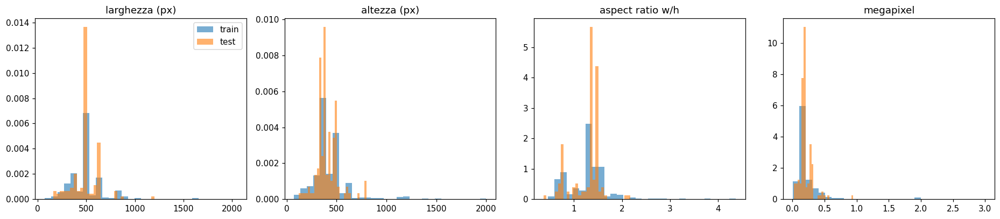

Dimensioni più frequenti:
split  w    h  
test   500  375    27
            333    12
       375  500     8
       640  480     7
       500  334     3
train  500  375    86
       375  500    36
       500  333    24
       640  480    20
       333  500    15
Name: count, dtype: int64

Immagini con lato max > 1000: 17 | < 300: 33


In [6]:
print(img.groupby("split")[["w", "h", "aspect", "megapixel"]].describe().T.round(2))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for s, c in [("train", "C0"), ("test", "C1")]:
    d = img[img.split == s]
    ax[0].hist(d.w, bins=30, alpha=.6, label=s, color=c, density=True); ax[1].hist(d.h, bins=30, alpha=.6, color=c, density=True)
    ax[2].hist(d.aspect, bins=30, alpha=.6, color=c, density=True); ax[3].hist(d.megapixel, bins=30, alpha=.6, color=c, density=True)
for a, t in zip(ax, ["larghezza (px)", "altezza (px)", "aspect ratio w/h", "megapixel"]): a.set_title(t)
ax[0].legend(); plt.tight_layout(); plt.show()

print("Dimensioni più frequenti:"); print(img.groupby("split").apply(lambda d: d[["w","h"]].value_counts().head(5)))
print("\nImmagini con lato max > 1000:", (img[["w","h"]].max(axis=1) > 1000).sum(), "| < 300:", (img[["w","h"]].max(axis=1) < 300).sum())

role   both  source only  target only
split                                
test     14           71           44
train    39          282          196

Coppie per immagine:
       count  mean   std  min  25%  50%  75%  max
split                                            
test   129.0  1.52  1.23  1.0  1.0  1.0  1.0  8.0
train  517.0  1.52  1.11  1.0  1.0  1.0  2.0  9.0


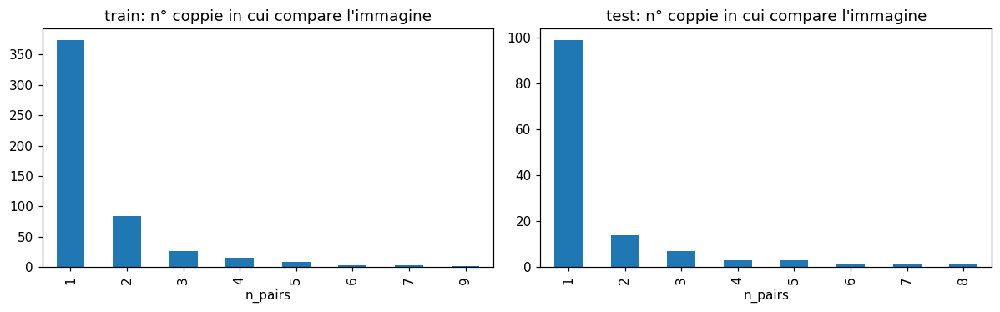

train: coppie duplicate (stessa direzione): 0 | coppie con inverso presente: 0 | src==tgt: 0
test: coppie duplicate (stessa direzione): 0 | coppie con inverso presente: 0 | src==tgt: 0


In [7]:
# Riuso delle immagini: quante coppie per immagine, e in che ruolo
img["role"] = np.select([(img.n_as_source > 0) & (img.n_as_target > 0), img.n_as_source > 0], ["both", "source only"], "target only")
print(pd.crosstab(img.split, img.role))
print("\nCoppie per immagine:"); print(img.groupby("split")["n_pairs"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, s in zip(ax, ["train", "test"]):
    img[img.split == s]["n_pairs"].value_counts().sort_index().plot.bar(ax=a); a.set_title(f"{s}: n° coppie in cui compare l'immagine")
plt.tight_layout(); plt.show()

# Coppie degeneri / simmetriche
for s in ["train", "test"]:
    d = pdf[pdf.split == s]
    rev = set(zip(d.target_image, d.source_image)); fw = set(zip(d.source_image, d.target_image))
    print(f"{s}: coppie duplicate (stessa direzione): {d.duplicated(['source_image','target_image']).sum()} | coppie con inverso presente: {len(rev & fw)} | src==tgt: {(d.source_image==d.target_image).sum()}")

> **Perché conta:** se la stessa immagine compare in più coppie, uno split casuale *per query o per coppia* produce **leakage** nella validazione. Più sotto (sez. 10) costruiamo uno split per componenti connesse del grafo delle immagini.

## 3. Coppie e query

== train == coppie: 392 | query: 2495 | source point totali nel JSON: 3410 | coppie senza query: 0
              count  mean   std   min   25%   50%   75%   max
n_src_points  392.0  8.70  3.13  3.00  6.00  8.00  11.0  18.0
n_queries     392.0  6.36  2.33  3.00  5.00  6.00   7.0  18.0
frac_labeled  392.0  0.76  0.20  0.25  0.62  0.78   1.0   1.0


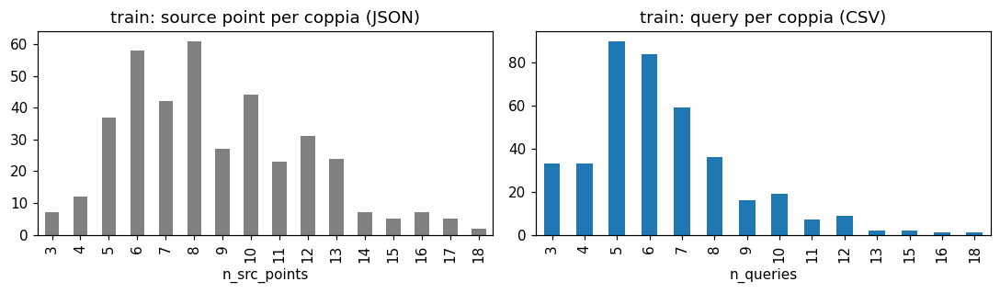

== test == coppie: 98 | query: 577 | source point totali nel JSON: 898 | coppie senza query: 0
              count  mean   std   min   25%   50%    75%   max
n_src_points   98.0  9.16  3.10  4.00  7.00  9.00  11.00  17.0
n_queries      98.0  5.89  2.27  3.00  5.00  5.00   7.00  12.0
frac_labeled   98.0  0.68  0.22  0.23  0.51  0.67   0.87   1.0


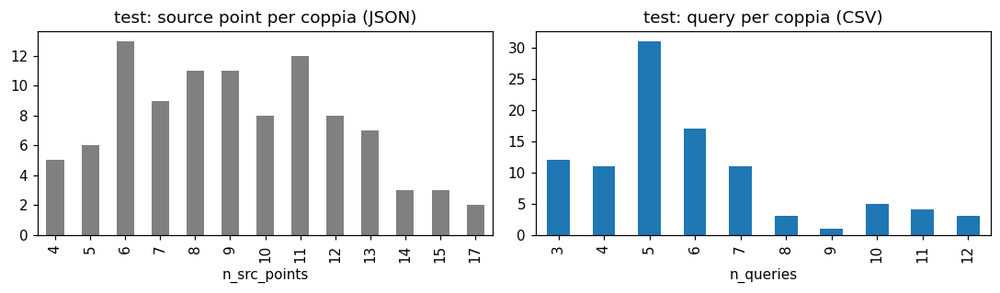

In [8]:
qtr = train.merge(pdf[pdf.split == "train"].drop(columns="split"), on="pair_id", suffixes=("", "_p"))
qte = test.merge(pdf[pdf.split == "test"].drop(columns="split"), on="pair_id", suffixes=("", "_p"))

for s, q in [("train", qtr), ("test", qte)]:
    pp = pdf[pdf.split == s].copy()
    pp["n_queries"] = pp.pair_id.map(q.groupby("pair_id").size()).fillna(0).astype(int)
    pp["frac_labeled"] = pp.n_queries / pp.n_src_points
    print(f"== {s} == coppie: {len(pp)} | query: {pp.n_queries.sum()} | source point totali nel JSON: {pp.n_src_points.sum()} "
          f"| coppie senza query: {(pp.n_queries==0).sum()}")
    print(pp[["n_src_points", "n_queries", "frac_labeled"]].describe().round(2).T)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    pp.n_src_points.value_counts().sort_index().plot.bar(ax=ax[0], color="gray"); ax[0].set_title(f"{s}: source point per coppia (JSON)")
    pp.n_queries.value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title(f"{s}: query per coppia (CSV)")
    plt.tight_layout(); plt.show()

In [9]:
# Le query della stessa coppia: quanto sono vicine fra loro nel source? (utile se si vuole sfruttare il contesto: gli altri source point)
def nn_dist_norm(q, pairs):
    out = []
    for pid, g in q.groupby("pair_id"):
        p = pairs[pid]; pts = np.array(p["source_xy"]); 
        if len(pts) < 2: continue
        d = np.linalg.norm(pts[:, None] - pts[None], axis=-1); np.fill_diagonal(d, np.inf)
        out += list(d.min(1) / max(p["source_size"]))
    return np.array(out)
for s, q in [("train", qtr), ("test", qte)]:
    d = nn_dist_norm(q, PAIRS[s]); print(f"{s}: distanza al source point più vicino (/lato max immagine): median={np.median(d):.3f}, p10={np.percentile(d,10):.3f}")

train: distanza al source point più vicino (/lato max immagine): median=0.072, p10=0.023
test: distanza al source point più vicino (/lato max immagine): median=0.057, p10=0.022


## 4. Target: multi-target e dispersione
Alcune query accettano **più target** (es. più ruote). La predizione è corretta se è vicina a *uno qualsiasi*: significa che basta scegliere un'istanza, ma anche che un modello che "media" fra le istanze fallisce.

n_targets
1    1185
2     969
3     120
4     161
5      10
6      50
Name: n_query, dtype: int64

Frazione query multi-target: 52.5%

Dispersione max fra alternative / L (solo multi-target):
count    1310.00
mean        0.45
std         0.29
min         0.02
25%         0.21
50%         0.38
75%         0.68
max         1.19
Name: spread_over_L, dtype: float64
Alternative più distanti di 0.2·L (cerchi disgiunti, 'mediare' = errore): 77.6%


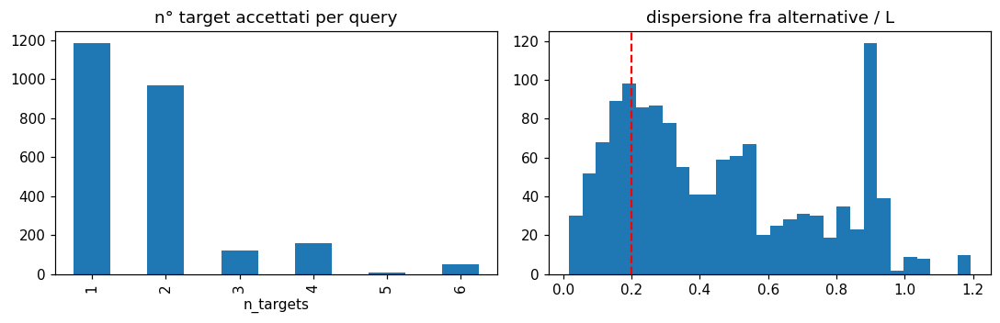

Punti target fuori dall'immagine: 0 | query con target fuori: 0
train: source point fuori immagine: 0
test: source point fuori immagine: 0


In [10]:
qtr["n_targets"] = qtr.target_points.apply(len)
print(qtr.n_targets.value_counts().sort_index().rename("n_query"))
print(f"\nFrazione query multi-target: {(qtr.n_targets > 1).mean():.1%}")

def spread(pts, L):
    P = np.array(pts); 
    if len(P) < 2: return 0.0
    return np.linalg.norm(P[:, None] - P[None], axis=-1).max() / L
qtr["spread_over_L"] = qtr.apply(lambda r: spread(r.target_points, r.scale), axis=1)
m = qtr[qtr.n_targets > 1]
print("\nDispersione max fra alternative / L (solo multi-target):"); print(m.spread_over_L.describe().round(2))
print(f"Alternative più distanti di 0.2·L (cerchi disgiunti, 'mediare' = errore): {(m.spread_over_L > 0.2).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
qtr.n_targets.value_counts().sort_index().plot.bar(ax=ax[0]); ax[0].set_title("n° target accettati per query")
ax[1].hist(m.spread_over_L, bins=30); ax[1].axvline(.2, c="r", ls="--"); ax[1].set_title("dispersione fra alternative / L")
plt.tight_layout(); plt.show()

# Alcune query hanno punti target duplicati o fuori immagine?
oob = qtr.apply(lambda r: sum(not (0 <= x <= r.tw and 0 <= y <= r.th) for x, y in r.target_points), axis=1)
print("Punti target fuori dall'immagine:", int(oob.sum()), "| query con target fuori:", int((oob > 0).sum()))
for s, q in [("train", qtr), ("test", qte)]:
    o = ((q.source_x < 0) | (q.source_x > q.sw) | (q.source_y < 0) | (q.source_y > q.sh)).sum(); print(f"{s}: source point fuori immagine: {o}")

## 5. Scala `L` e raggio di tolleranza
Il raggio di tolleranza vale `0.10 · L` pixel. Se `L` è piccola rispetto all'immagine, il match deve essere preciso a livello di pochi pixel — e con feature a risoluzione di patch (14/16 px) la **risoluzione delle feature diventa il limite**.

                   count     mean      std     min      5%     25%      50%      75%      95%       max
scale             2495.0  265.099  206.684  29.700  51.700  89.489  221.100  377.300  649.629  1449.374
radius_px         2495.0   26.510   20.668   2.970   5.170   8.949   22.110   37.730   64.963   144.937
L_rel             2495.0    0.446    0.288   0.059   0.083   0.165    0.426    0.689    0.940     1.061
circle_area_frac  2495.0    0.012    0.013   0.000   0.000   0.001    0.008    0.019    0.039     0.068


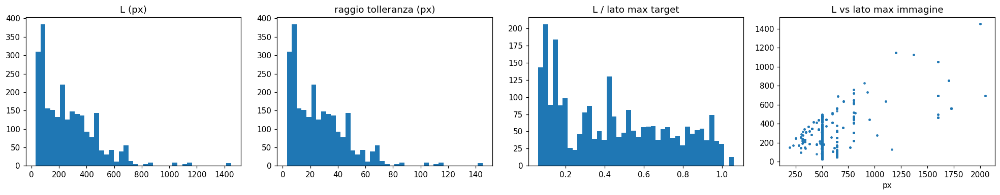

Query con raggio < 8 px : 21.8% | < 16 px: 39.0% | < 32 px: 66.1%
Query con L < 25% del lato max (oggetti piccoli): 34.0%
S=448: raggio tolleranza / cella-patch  mediana=1.36  (<1 per il 39.3% delle query)
S=518: raggio tolleranza / cella-patch  mediana=1.58  (<1 per il 34.8% delle query)
S=768: raggio tolleranza / cella-patch  mediana=2.34  (<1 per il 28.5% delle query)


In [11]:
qtr["radius_px"] = 0.10 * qtr.scale
qtr["L_rel"] = qtr.scale / qtr[["tw", "th"]].max(axis=1)            # L / lato max del target
qtr["L_rel_diag"] = qtr.scale / np.hypot(qtr.tw, qtr.th)
qtr["circle_area_frac"] = np.pi * qtr.radius_px**2 / (qtr.tw * qtr.th)   # quota immagine target "coperta" da un cerchio corretto
print(qtr[["scale", "radius_px", "L_rel", "circle_area_frac"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(3).T)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].hist(qtr.scale, bins=40); ax[0].set_title("L (px)")
ax[1].hist(qtr.radius_px, bins=40); ax[1].set_title("raggio tolleranza (px)")
ax[2].hist(qtr.L_rel, bins=40); ax[2].set_title("L / lato max target")
ax[3].scatter(qtr[["tw", "th"]].max(axis=1), qtr.scale, s=4, alpha=.4); ax[3].set_title("L vs lato max immagine"); ax[3].set_xlabel("px")
plt.tight_layout(); plt.show()

print("Query con raggio < 8 px :", f"{(qtr.radius_px < 8).mean():.1%}", "| < 16 px:", f"{(qtr.radius_px < 16).mean():.1%}", "| < 32 px:", f"{(qtr.radius_px < 32).mean():.1%}")
print("Query con L < 25% del lato max (oggetti piccoli):", f"{(qtr.L_rel < .25).mean():.1%}")
# Rapporto fra scala di L e dimensione patch DINO (14 px su immagine ridimensionata)
for S in [448, 518, 768]:
    cell_px = qtr[["tw", "th"]].max(axis=1) / (S / 14)    # px originali per cella 14x14 se l'immagine è ridimensionata a S
    print(f"S={S}: raggio tolleranza / cella-patch  mediana={np.median(qtr.radius_px / cell_px):.2f}  (<1 per il {(qtr.radius_px < cell_px).mean():.1%} delle query)")

In [12]:
# L dipende dal numero di target? L è una per query (bbox target): confronto per n_targets
print(qtr.groupby(qtr.n_targets.clip(upper=4))[["scale", "L_rel"]].agg(["mean", "median", "count"]).round(2))
# Stessa coppia: L varia fra le query della stessa coppia?
g = qtr.groupby("pair_id")["scale"].agg(["min", "max", "count"]); g = g[g["count"] > 1]
print("\nCoppie con >1 query: rapporto max/min di L mediano =", round((g["max"] / g["min"]).median(), 2))

            scale               L_rel             
             mean  median count  mean median count
n_targets                                         
1          262.42  222.20  1185  0.43   0.43  1185
2          276.91  235.40   969  0.48   0.44   969
3          201.10  185.90   120  0.35   0.37   120
4          262.46  209.66   221  0.47   0.46   221

Coppie con >1 query: rapporto max/min di L mediano = 1.0


## 6. Distribuzione spaziale e baseline banali
Verifichiamo se c'è un bias di posizione (oggetti centrati?) e quanto "regalano" baseline senza apprendimento. Utile come **limite inferiore** da battere (il sample_submission usa il centro del target).

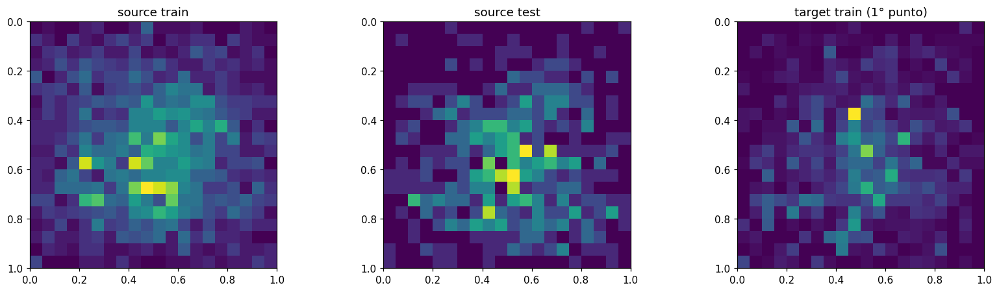

corr(sx_n, tx_n) = -0.115 | corr(sy_n, ty_n) = 0.294
spostamento normalizzato |dx|: median 0.215  |dy|: median 0.161

source point entro il 5% dal bordo: train 4.5% | test 2.4%


In [14]:
qtr["sx_n"] = qtr.source_x / qtr.sw; qtr["sy_n"] = qtr.source_y / qtr.sh
qte["sx_n"] = qte.source_x / qte.sw; qte["sy_n"] = qte.source_y / qte.sh
qtr["tn"] = qtr.apply(lambda r: [(x / r.tw, y / r.th) for x, y in r.target_points], axis=1)

tx = np.array([t[0][0] for t in qtr.tn]); ty = np.array([t[0][1] for t in qtr.tn])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (x, y, t) in zip(ax, [(qtr.sx_n, qtr.sy_n, "source train"), (qte.sx_n, qte.sy_n, "source test"), (tx, ty, "target train (1° punto)")]):
    h = a.hist2d(x, y, bins=20, range=[[0, 1], [0, 1]], cmap="viridis"); a.invert_yaxis(); a.set_title(t); a.set_aspect("equal")
plt.tight_layout(); plt.show()

# correlazione posizione normalizzata source -> target (stessa posizione?)
print("corr(sx_n, tx_n) =", round(np.corrcoef(qtr.sx_n, tx)[0, 1], 3), "| corr(sy_n, ty_n) =", round(np.corrcoef(qtr.sy_n, ty)[0, 1], 3))
dx = tx - qtr.sx_n.values; dy = ty - qtr.sy_n.values
print("spostamento normalizzato |dx|: median %.3f  |dy|: median %.3f" % (np.median(np.abs(dx)), np.median(np.abs(dy))))

# distanza dal bordo del source point
for q in (qtr, qte):
    q["border_dist"] = np.minimum.reduce([q.source_x, q.sw - q.source_x, q.source_y, q.sh - q.source_y]) / q[["sw", "sh"]].min(axis=1)
print("\nsource point entro il 5%% dal bordo: train %.1f%% | test %.1f%%" % ((qtr.border_dist < .05).mean() * 100, (qte.border_dist < .05).mean() * 100))

In [15]:
def correct(pred, targets, L, thr=0.10):
    return min(math.hypot(pred[0] - t[0], pred[1] - t[1]) for t in targets) / L <= thr

def pck(fn, df):
    return np.mean([correct(fn(r), r.target_points, r.scale) for r in df.itertuples()])

mean_tx, mean_ty = np.mean(tx), np.mean(ty)
baselines = {
    "centro del target (sample_submission)": lambda r: (r.tw / 2, r.th / 2),
    "stessa posizione normalizzata del source": lambda r: (r.source_x / r.sw * r.tw, r.source_y / r.sh * r.th),
    "stessa posizione in pixel (clip)": lambda r: (min(r.source_x, r.tw), min(r.source_y, r.th)),
    "media posizione target train": lambda r: (mean_tx * r.tw, mean_ty * r.th),
}
res = {k: pck(f, qtr) for k, f in baselines.items()}
print(pd.Series(res, name="PCK@0.10 (train)").round(4).to_string())

centro del target (sample_submission)       0.0345
stessa posizione normalizzata del source    0.0301
stessa posizione in pixel (clip)            0.0208
media posizione target train                0.0389


## 7. Shift train vs test

In [16]:
from scipy.stats import ks_2samp
feat = {
    "source w": (qtr.sw, qte.sw), "source h": (qtr.sh, qte.sh), "target w": (qtr.tw, qte.tw), "target h": (qtr.th, qte.th),
    "source aspect": (qtr.sw / qtr.sh, qte.sw / qte.sh), "target aspect": (qtr.tw / qtr.th, qte.tw / qte.th),
    "sx_n": (qtr.sx_n, qte.sx_n), "sy_n": (qtr.sy_n, qte.sy_n), "border_dist": (qtr.border_dist, qte.border_dist),
    "source/target area ratio": (qtr.sw * qtr.sh / (qtr.tw * qtr.th), qte.sw * qte.sh / (qte.tw * qte.th)),
}
rows = [(k, np.median(a), np.median(b), *ks_2samp(a, b)) for k, (a, b) in feat.items()]
print(pd.DataFrame(rows, columns=["feature", "median train", "median test", "KS stat", "p-value"]).round(4).to_string(index=False))
print("\nquery per coppia – train: %.2f | test: %.2f" % (len(qtr) / qtr.pair_id.nunique(), len(qte) / qte.pair_id.nunique()))

                 feature  median train  median test  KS stat  p-value
                source w      500.0000     500.0000   0.0628   0.0473
                source h      375.0000     375.0000   0.1131   0.0000
                target w      500.0000     500.0000   0.1168   0.0000
                target h      424.0000     426.0000   0.0744   0.0104
           source aspect        1.3333       1.3333   0.0988   0.0002
           target aspect        1.3333       1.3333   0.1191   0.0000
                    sx_n        0.5012       0.5260   0.0825   0.0032
                    sy_n        0.5455       0.5920   0.0939   0.0005
             border_dist        0.2835       0.2827   0.0617   0.0534
source/target area ratio        0.9930       1.0000   0.1156   0.0000

query per coppia – train: 6.36 | test: 5.89


> Nota: `scale` (L) **non è disponibile sul test**: il raggio di tolleranza non è noto a priori, quindi conviene stimare la dimensione dell'oggetto (es. dalla mappa di similarità / segmentazione) se si vuole raffinare la predizione.

## 8. Visualizzazioni qualitative (cerchi = tolleranza PCK@0.10)

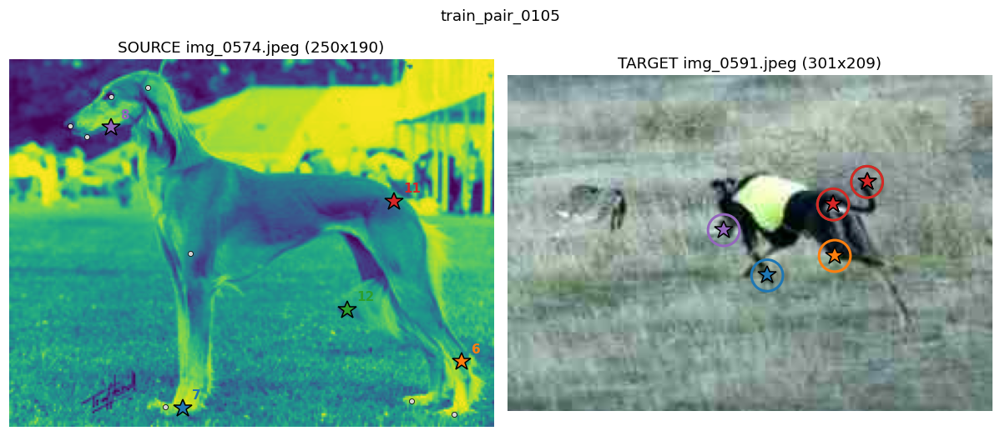

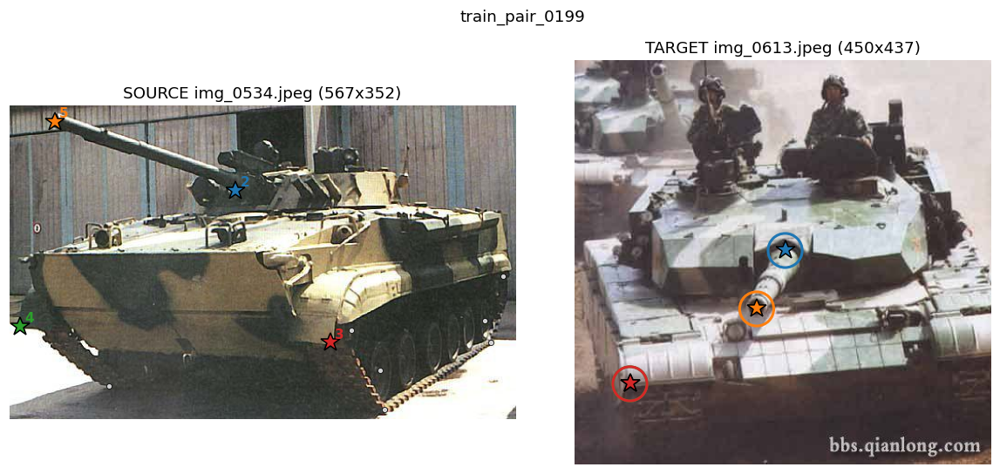

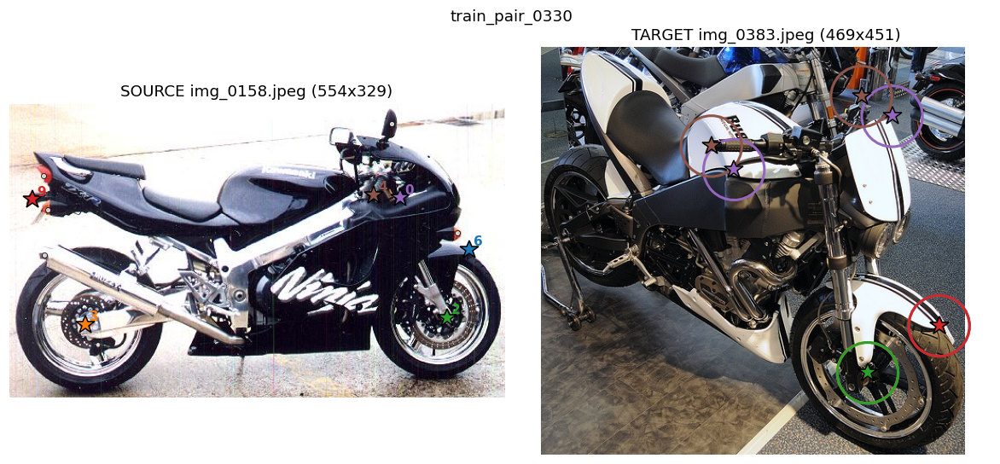

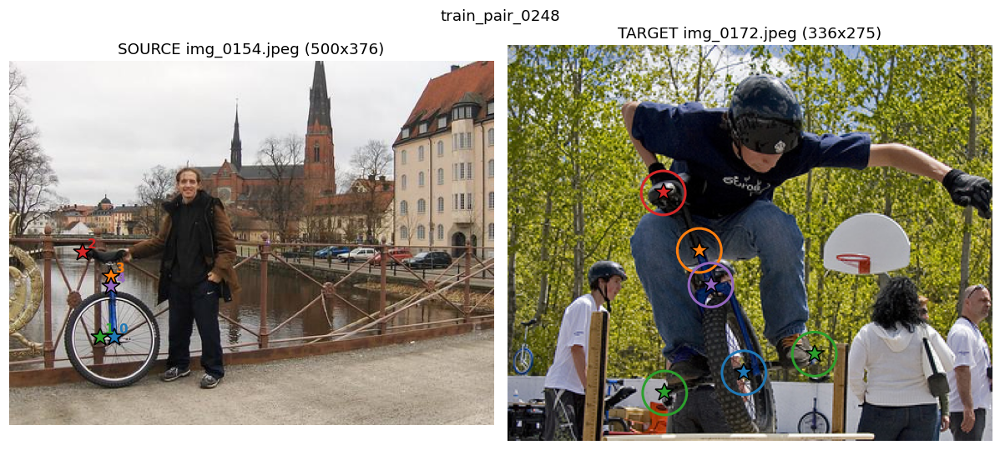

In [17]:
CMAP = plt.get_cmap("tab10")
def draw_pair(pair_id, split="train", preds=None, max_q=6, title=None):
    df = train if split == "train" else test
    meta = PAIRS[split][pair_id]; qs = df[df.pair_id == pair_id].head(max_q)
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    ax[0].imshow(Image.open(DATA_DIR / meta["source_image"])); ax[1].imshow(Image.open(DATA_DIR / meta["target_image"]))
    for p in meta["source_xy"]: ax[0].plot(p[0], p[1], "o", ms=4, color="lightgray", mec="k", mew=.5)   # contesto
    for k, r in enumerate(qs.itertuples()):
        c = CMAP(k % 10)
        ax[0].plot(r.source_x, r.source_y, "*", ms=15, color=c, mec="k"); ax[0].text(r.source_x + 5, r.source_y - 5, str(r.query_index), color=c, weight="bold")
        if split == "train":
            for t in r.target_points:
                ax[1].plot(t[0], t[1], "*", ms=15, color=c, mec="k"); ax[1].add_patch(Circle(t, .1 * r.scale, fill=False, color=c, lw=2))
        if preds is not None and r.id in preds:
            ax[1].plot(*preds[r.id], "X", ms=11, color=c, mec="w", mew=1.5)
    ax[0].set_title(f"SOURCE {meta['source_image'].split('/')[-1]} ({meta['source_size'][0]}x{meta['source_size'][1]})")
    ax[1].set_title(f"TARGET {meta['target_image'].split('/')[-1]} ({meta['target_size'][0]}x{meta['target_size'][1]})")
    for a in ax: a.axis("off")
    plt.suptitle(title or pair_id); plt.tight_layout(); plt.show()

for pid in rng.choice(sorted(PAIRS["train"]), 4, replace=False): draw_pair(pid, "train")

== Query multi-target ==


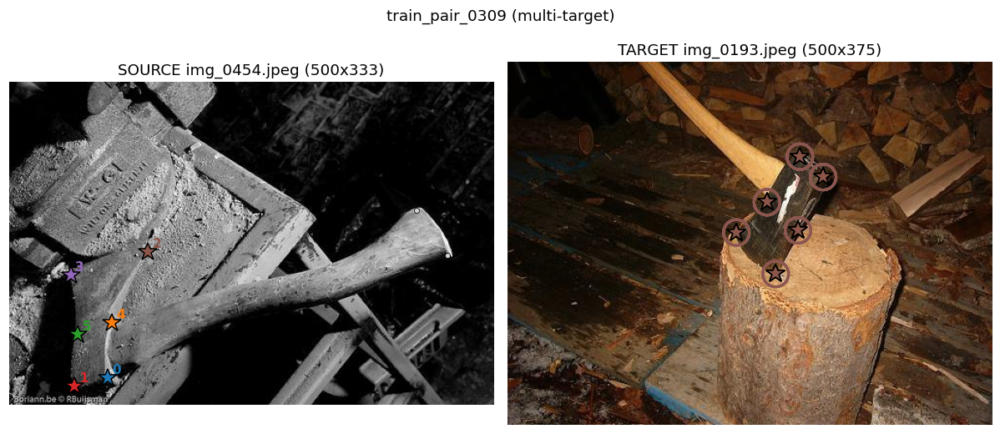

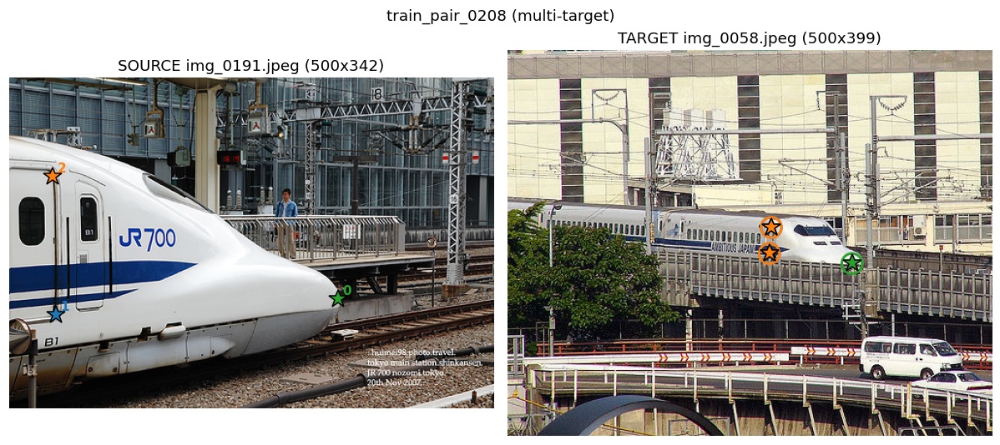

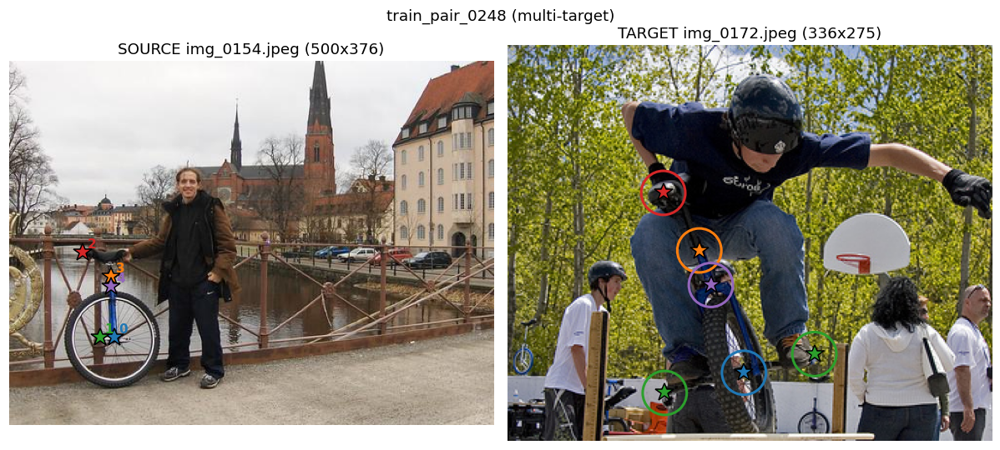

== Oggetti più piccoli (L_rel minima) ==


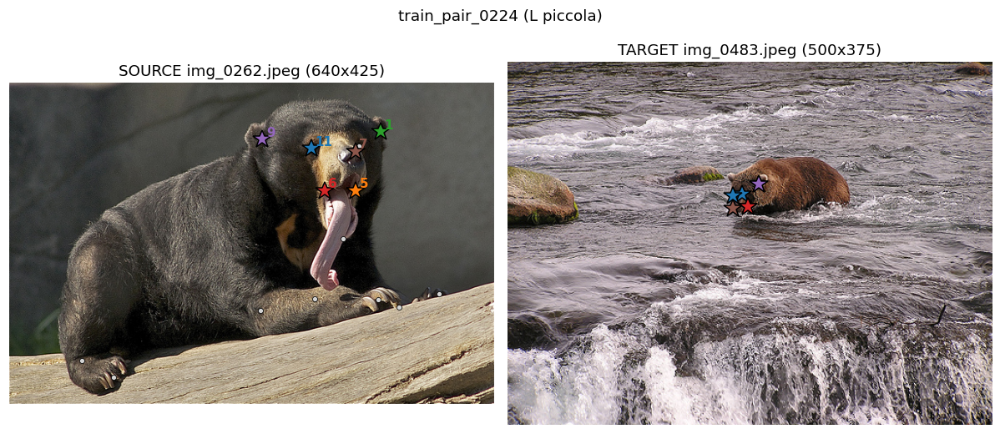

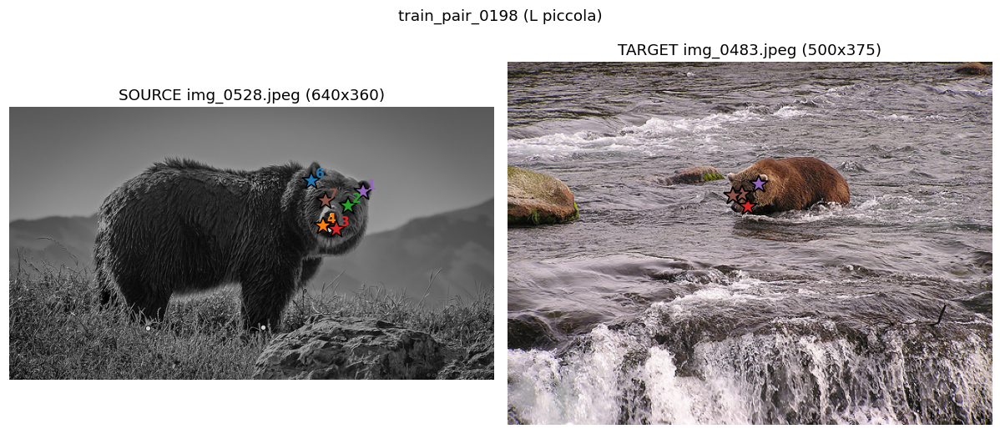

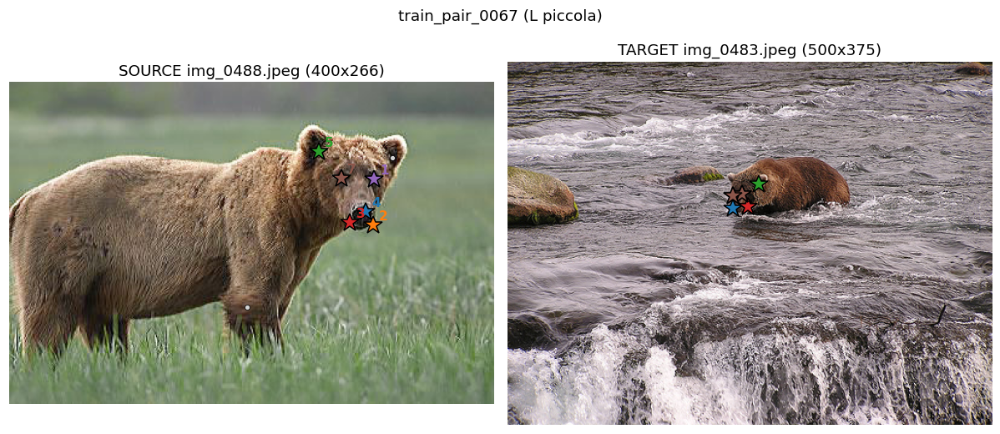

== Test (solo source) ==


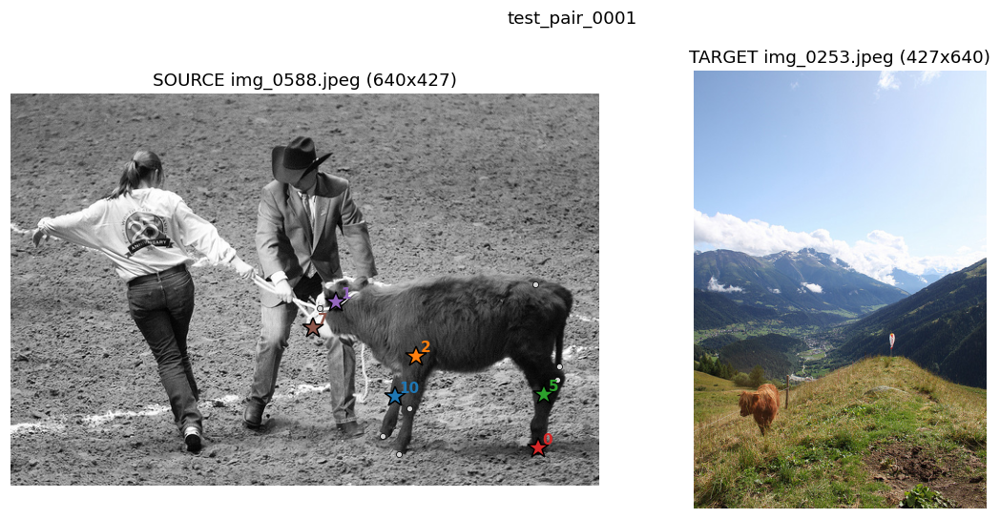

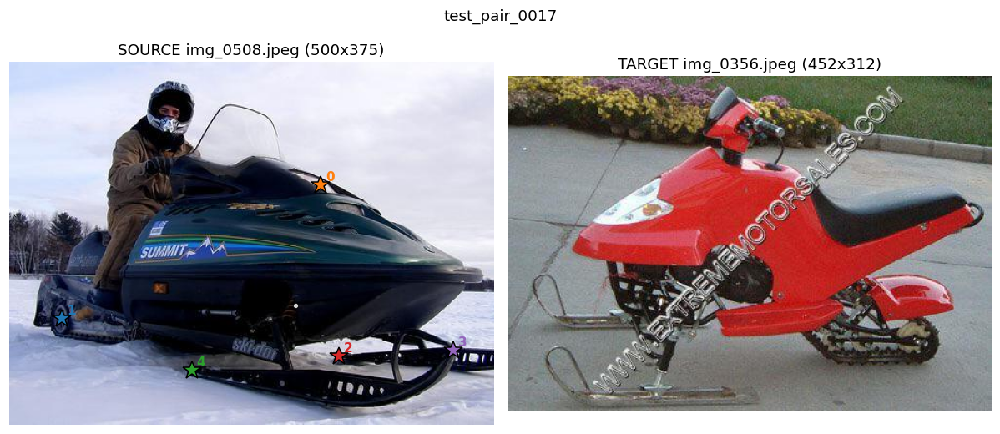

In [18]:
print("== Query multi-target =="); 
for pid in qtr[qtr.n_targets > 1].pair_id.drop_duplicates().sample(3, random_state=SEED): draw_pair(pid, "train", title=f"{pid} (multi-target)")
print("== Oggetti più piccoli (L_rel minima) ==")
for pid in qtr.sort_values("L_rel").pair_id.drop_duplicates().head(3): draw_pair(pid, "train", title=f"{pid} (L piccola)")
print("== Test (solo source) ==")
for pid in rng.choice(sorted(PAIRS["test"]), 2, replace=False): draw_pair(pid, "test")

## 9. Baseline con feature dense (DINOv2) + analisi dell'errore
Non è l'EDA "pura", ma serve a capire **dove** il nearest-neighbor sui feature dense fallisce (scala piccola, multi-target, bordi…), cioè dove investire. Metti `RUN_BASELINE = False` per saltare. Per usare DINOv3 basta cambiare `MODEL_NAME` (richiede accesso al modello su HuggingFace).

In [19]:
RUN_BASELINE = True
MODEL_NAME   = "facebook/dinov2-base"
S            = 448            # lato (multiplo di PATCH) a cui si ridimensiona l'immagine (senza preservare aspect ratio)
PATCH        = 14
N_PAIRS_EVAL = 80             # sottoinsieme di coppie train per velocità

if RUN_BASELINE:
    import torch, torch.nn.functional as F
    from transformers import AutoModel
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
    G = S // PATCH
    MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1); STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    _cache = {}

    @torch.no_grad()
    def get_feat(path):
        if path in _cache: return _cache[path]
        im = Image.open(DATA_DIR / path).convert("RGB"); w, h = im.size
        x = torch.from_numpy(np.asarray(im.resize((S, S), Image.BICUBIC)).copy()).permute(2, 0, 1).float() / 255
        out = model(pixel_values=((x - MEAN) / STD).unsqueeze(0).to(device)).last_hidden_state[0]
        cls = out[0].float().cpu(); patch = F.normalize(out[-G * G:].float(), dim=-1).reshape(G, G, -1).cpu()
        _cache[path] = (cls, patch, (w, h)); return _cache[path]

    def nn_predict(src, tgt, sx, sy):
        _, fs, (sw, sh) = get_feat(src); _, ft, (tw, th) = get_feat(tgt)
        gx = min(int(sx / sw * G), G - 1); gy = min(int(sy / sh * G), G - 1)
        sim = ft @ fs[gy, gx]
        iy, ix = np.unravel_index(int(sim.argmax()), sim.shape)
        return ((ix + .5) / G * tw, (iy + .5) / G * th), float(sim.max())

    pids = rng.choice(sorted(qtr.pair_id.unique()), min(N_PAIRS_EVAL, qtr.pair_id.nunique()), replace=False)
    ev = qtr[qtr.pair_id.isin(pids)].copy()
    out = [nn_predict(r.source_image, r.target_image, r.source_x, r.source_y) for r in ev.itertuples()]
    ev["pred"] = [o[0] for o in out]; ev["sim"] = [o[1] for o in out]
    ev["dist_norm"] = [min(math.hypot(r.pred[0] - t[0], r.pred[1] - t[1]) for t in r.target_points) / r.scale for r in ev.itertuples()]
    ev["ok"] = ev.dist_norm <= .10
    print(f"[{MODEL_NAME} | S={S}] NN baseline PCK@0.10 su {len(ev)} query ({len(pids)} coppie): {ev.ok.mean():.3f}")

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[facebook/dinov2-base | S=448] NN baseline PCK@0.10 su 532 query (80 coppie): 0.370


PCK per quartile di L/lato-max-target:
                    PCK  count
L_rel                        
(0.0584, 0.112]  0.218    142
(0.112, 0.394]   0.569    130
(0.394, 0.627]   0.305    131
(0.627, 0.975]   0.403    129

PCK per n° target accettati:
             mean  count
n_targets              
1          0.320    253
2          0.433    224
3          0.345     55

PCK per distanza dal bordo del source (quartili):
                   PCK  count
border_dist                 
(0.007, 0.162]  0.368    133
(0.162, 0.281]  0.331    133
(0.281, 0.36]   0.338    133
(0.36, 0.498]   0.444    133

PCK per quartile di similarità (confidenza):
                   PCK  count
sim                         
(0.166, 0.468]  0.226    133
(0.468, 0.581]  0.466    133
(0.581, 0.676]  0.406    133
(0.676, 0.941]  0.383    133

Errore: quota di predizioni sbagliate ma entro 0.25·L (quasi corrette, limite di risoluzione): 49.3%


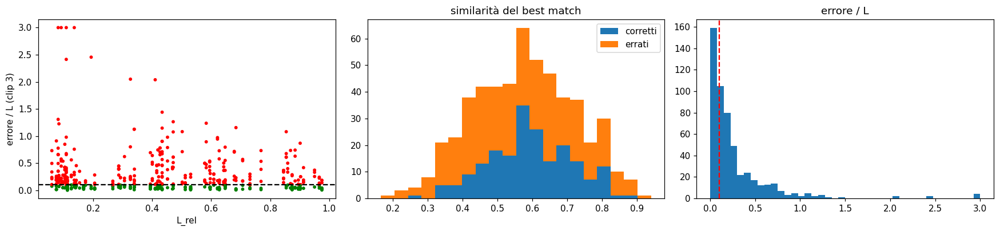

In [20]:
if RUN_BASELINE:
    def by_bin(col, q=4, name=None):
        b = pd.qcut(ev[col], q, duplicates="drop") if isinstance(q, int) else pd.cut(ev[col], q)
        return ev.groupby(b).ok.agg(["mean", "count"]).rename(columns={"mean": "PCK"}).round(3)
    print("PCK per quartile di L/lato-max-target:\n", by_bin("L_rel"))
    print("\nPCK per n° target accettati:\n", ev.groupby(ev.n_targets.clip(upper=3)).ok.agg(["mean", "count"]).round(3))
    print("\nPCK per distanza dal bordo del source (quartili):\n", by_bin("border_dist"))
    print("\nPCK per quartile di similarità (confidenza):\n", by_bin("sim"))
    print("\nErrore: quota di predizioni sbagliate ma entro 0.25·L (quasi corrette, limite di risoluzione):",
          f"{((~ev.ok) & (ev.dist_norm <= .25)).sum() / max((~ev.ok).sum(), 1):.1%}")

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].scatter(ev.L_rel, ev.dist_norm.clip(upper=3), s=8, c=ev.ok.map({True: "g", False: "r"})); ax[0].axhline(.1, ls="--", c="k"); ax[0].set_xlabel("L_rel"); ax[0].set_ylabel("errore / L (clip 3)")
    ax[1].hist([ev[ev.ok].sim, ev[~ev.ok].sim], bins=20, label=["corretti", "errati"], stacked=True); ax[1].legend(); ax[1].set_title("similarità del best match")
    ax[2].hist(ev.dist_norm.clip(upper=3), bins=40); ax[2].axvline(.1, c="r", ls="--"); ax[2].set_title("errore / L")
    plt.tight_layout(); plt.show()

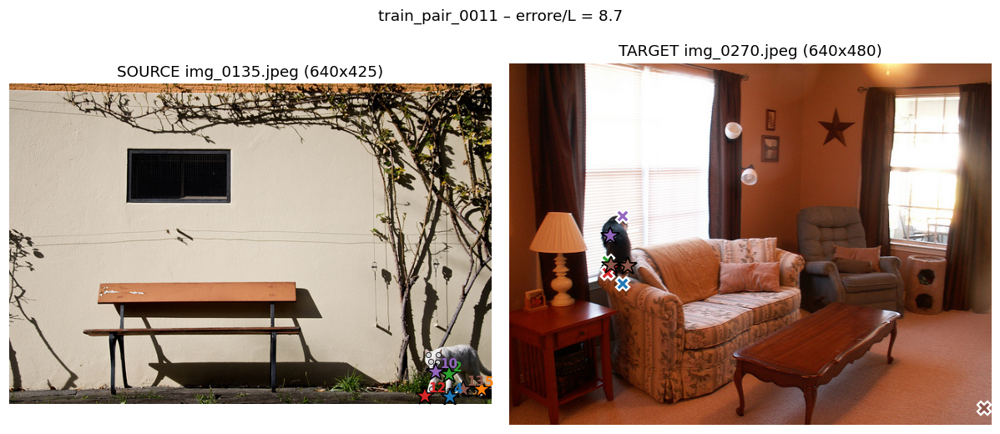

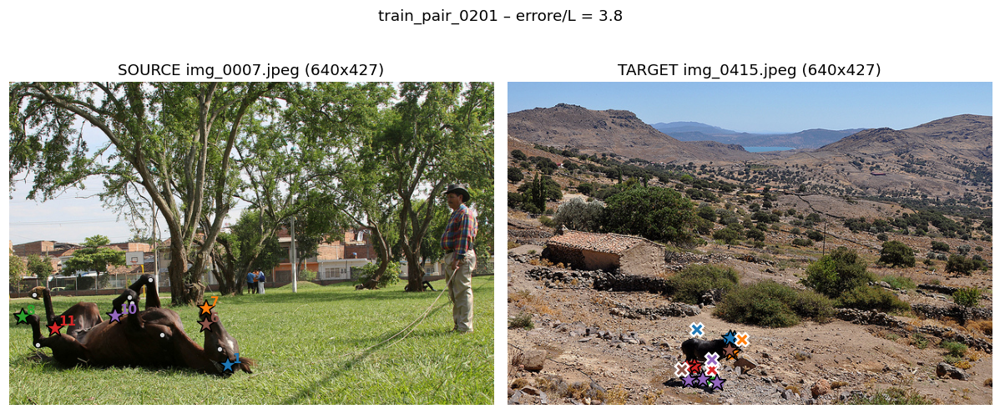

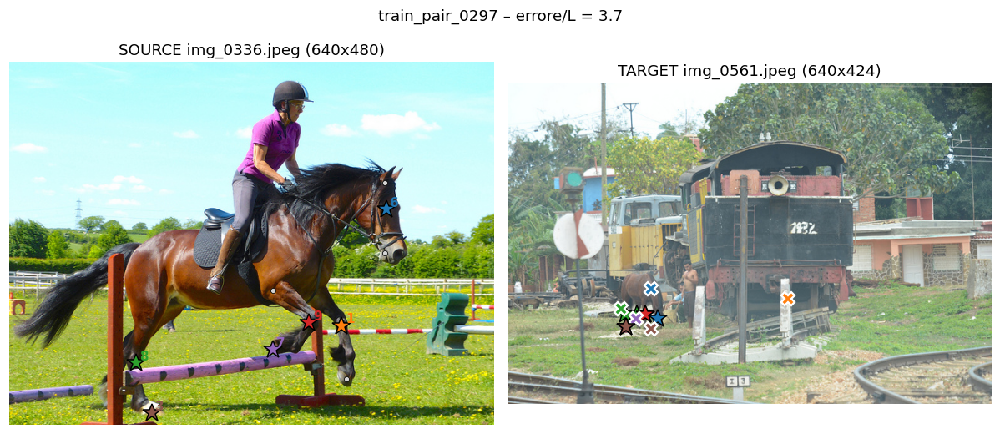

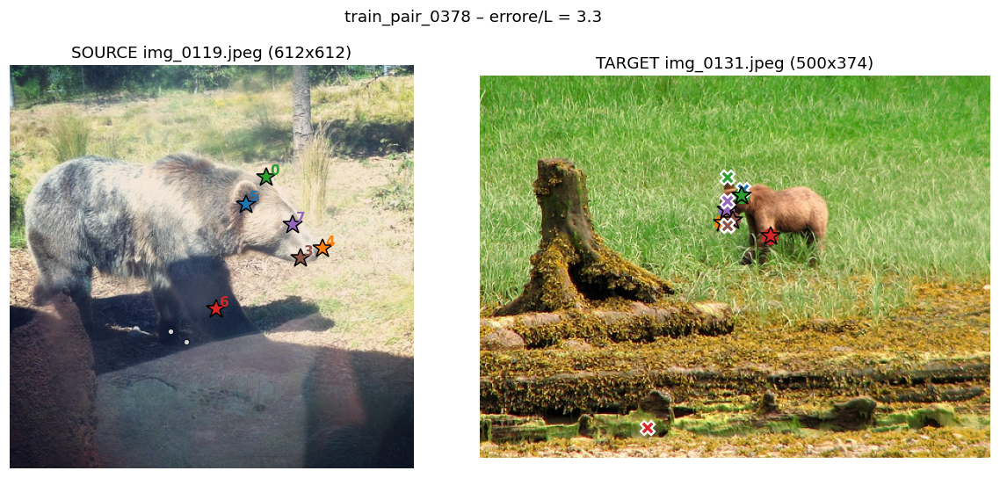

In [21]:
if RUN_BASELINE:
    # Galleria dei fallimenti peggiori (X = predizione)
    worst = ev.sort_values("dist_norm", ascending=False).drop_duplicates("pair_id").head(4)
    for r in worst.itertuples():
        draw_pair(r.pair_id, "train", preds={x.id: x.pred for x in ev[ev.pair_id == r.pair_id].itertuples()}, title=f"{r.pair_id} – errore/L = {r.dist_norm:.1f}")

In [22]:
# Separabilità semantica: quanto il test è "vicino" al train nello spazio delle feature globali (CLS)?
if RUN_BASELINE:
    sample = lambda s, n: rng.choice(img[img.split == s].path.values, min(n, (img.split == s).sum()), replace=False)
    tr_p, te_p = sample("train", 150), sample("test", 100)
    E = lambda ps: F.normalize(torch.stack([get_feat(p)[0] for p in ps]), dim=-1)
    Etr, Ete = E(tr_p), E(te_p)
    nn_te = (Ete @ Etr.T).max(1).values; nn_tr = ((Etr @ Etr.T) - 2 * torch.eye(len(Etr))).max(1).values
    print(f"sim NN test→train: mediana {nn_te.median():.3f} | train→train (leave-one-out): mediana {nn_tr.median():.3f}")
    from sklearn.cluster import KMeans
    km = KMeans(8, n_init=10, random_state=SEED).fit(torch.cat([Etr, Ete]).numpy())
    lab = km.labels_; print(pd.crosstab(pd.Series(["train"] * len(Etr) + ["test"] * len(Ete), name="split"), pd.Series(lab, name="cluster")))

sim NN test→train: mediana 0.451 | train→train (leave-one-out): mediana 0.608
cluster  0   1   2   3   4  5   6   7
split                                
test     6  37   0  10  16  7  20   4
train    9  51  13  15  14  9  15  24


## 10. Split di validazione senza leakage
Costruiamo il grafo delle immagini (nodo = immagine, arco = coppia) e usiamo le **componenti connesse** come gruppi per `GroupKFold`: nessuna immagine compare contemporaneamente in train-fold e val-fold (stessa logica con cui train/test sono stati separati dagli organizzatori).

In [23]:
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
def union(a, b): parent[find(a)] = find(b)
for p in train_pairs: union(p["source_image"], p["target_image"])

comp = {i: find(i) for i in img[img.split == "train"].path}
cid = {c: k for k, c in enumerate(sorted(set(comp.values())))}
pair_group = {p["pair_id"]: cid[comp[p["source_image"]]] for p in train_pairs}
qtr["group"] = qtr.pair_id.map(pair_group)
sizes = qtr.groupby("group").size().sort_values(ascending=False)
print("Componenti connesse (gruppi):", len(cid), "| query nel gruppo più grande:", sizes.iloc[0], f"({sizes.iloc[0]/len(qtr):.1%})")
print(sizes.describe().round(1).T)

from sklearn.model_selection import GroupKFold
gkf = GroupKFold(n_splits=5); qtr["fold"] = -1
for k, (_, vi) in enumerate(gkf.split(qtr, groups=qtr.group)): qtr.iloc[vi, qtr.columns.get_loc("fold")] = k
print("\nQuery per fold:", qtr.fold.value_counts().sort_index().tolist())
leak = [len(set(pd.concat([qtr[qtr.fold == k].source_image, qtr[qtr.fold == k].target_image])) &
            set(pd.concat([qtr[qtr.fold != k].source_image, qtr[qtr.fold != k].target_image]))) for k in range(5)]
print("Immagini condivise fra val e train per fold (deve essere 0):", leak)
print(qtr.groupby("fold")[["scale", "L_rel", "n_targets"]].mean().round(3))

Componenti connesse (gruppi): 142 | query nel gruppo più grande: 243 (9.7%)
count    142.0
mean      17.6
std       27.3
min        3.0
25%        6.0
50%       10.0
75%       18.0
max      243.0
dtype: float64

Query per fold: [498, 500, 500, 500, 497]
Immagini condivise fra val e train per fold (deve essere 0): [0, 0, 0, 0, 0]
        scale  L_rel  n_targets
fold                           
0     195.234  0.343      1.863
1     292.615  0.421      1.858
2     325.112  0.552      1.704
3     245.801  0.453      1.998
4     266.460  0.460      1.547


## 11. Riepilogo automatico

In [24]:
print("=== RIEPILOGO ===")
print(f"Query: train {len(qtr)} | test {len(qte)}  |  coppie: train {len(train_pairs)} | test {len(test_pairs)}  |  immagini: {img.split.value_counts().to_dict()}")
print(f"Multi-target: {(qtr.n_targets > 1).mean():.1%} delle query train (max {qtr.n_targets.max()} alternative)")
print(f"L mediana: {qtr.scale.median():.0f}px (raggio tolleranza {qtr.radius_px.median():.0f}px) | L/lato max target mediana: {qtr.L_rel.median():.2f}")
print(f"Query con raggio < 16px: {(qtr.radius_px < 16).mean():.1%}")
print(f"Immagini riusate in >1 coppia (train): {(img[img.split=='train'].n_pairs > 1).mean():.1%}  -> usare GroupKFold per componenti connesse")
print("Baseline banali PCK:", {k[:22]: round(v, 3) for k, v in res.items()})
if RUN_BASELINE: print(f"NN DINO baseline PCK (sottoinsieme): {ev.ok.mean():.3f}")

=== RIEPILOGO ===
Query: train 2495 | test 577  |  coppie: train 392 | test 98  |  immagini: {'train': 517, 'test': 129}
Multi-target: 52.5% delle query train (max 6 alternative)
L mediana: 221px (raggio tolleranza 22px) | L/lato max target mediana: 0.43
Query con raggio < 16px: 39.0%
Immagini riusate in >1 coppia (train): 27.7%  -> usare GroupKFold per componenti connesse
Baseline banali PCK: {'centro del target (sam': np.float64(0.034), 'stessa posizione norma': np.float64(0.03), 'stessa posizione in pi': np.float64(0.021), 'media posizione target': np.float64(0.039)}
NN DINO baseline PCK (sottoinsieme): 0.370


### Spunti per il modeling (da verificare con i numeri sopra)
- **Risoluzione**: se il raggio di tolleranza è spesso < 1 cella-patch, servono feature ad alta risoluzione (immagini più grandi, multi-scala, upsampling/FeatUp-like) e **raffinamento sub-patch** (soft-argmax / peso sui vicini della similarità, o crop attorno al match e ripetizione).
- **Multi-target**: basta un'istanza → evitare soft-argmax globale fra più picchi; scegliere il picco migliore, poi raffinare localmente.
- **Oggetti piccoli / sfondo**: stimare l'oggetto nel target (mappa di salienza, cluster di feature, SAM) e restringere la ricerca; il match del contesto (altri `source_xy`) può aiutare.
- **Simmetrie / parti ripetute** (sx/dx, 4 zampe): ensemble di feature (DINOv2 + Stable Diffusion/SD-DINO), flip-augmentation, vincoli geometrici sul contesto dei source point.
- **Fine-tuning**: poche coppie (392) → fine-tuning leggero (adapter / ultimi blocchi / LoRA) con loss su correspondence e validazione con lo split a gruppi della sez. 10.
- `scale` non è nel test: eventuali metodi adattivi alla scala devono stimarla.